# CIFAR-10 Robust Classification — Kaggle Starter
Run cells from top to bottom. This notebook is a structured starter for the assignment.
**Before reporting final results:** add the instructor's exact hidden corruption and complete the marked ablation TODOs. Do not report scores until they come from your own run.

## 1. Setup

In [1]:
import os, copy, random, time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import Dataset, DataLoader
from torchvision import datasets, transforms
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay, classification_report

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
DATA_ROOT = "/kaggle/working/cifar10_data"
SEEDS = [42, 123, 2026]
BATCH_SIZE = 64
MAX_EPOCHS = 60
NUM_WORKERS = 2
print("Device:", DEVICE)

Device: cuda


## 2. Reproducibility

In [2]:
def set_seed(seed):
    random.seed(seed); np.random.seed(seed)
    torch.manual_seed(seed); torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False

set_seed(SEEDS[0])

## 3. Load CIFAR-10

In [3]:
os.makedirs(DATA_ROOT, exist_ok=True)
train_raw = datasets.CIFAR10(DATA_ROOT, train=True, download=True, transform=None)
test_raw = datasets.CIFAR10(DATA_ROOT, train=False, download=True, transform=None)
CLASS_NAMES = train_raw.classes
targets = np.array(train_raw.targets)
print("Classes:", CLASS_NAMES)
print("Train:", len(train_raw), "| Clean test:", len(test_raw))

100%|██████████| 170M/170M [36:54<00:00, 77.0kB/s] 


Classes: ['airplane', 'automobile', 'bird', 'cat', 'deer', 'dog', 'frog', 'horse', 'ship', 'truck']
Train: 50000 | Clean test: 10000


## 4. Select 500 images and split

In [4]:
selected = []
rng = np.random.default_rng(SEEDS[0])
for c in range(10):
    ids = np.where(targets == c)[0]
    selected.extend(rng.choice(ids, 50, replace=False).tolist())
train_indices, val_indices = [], []
for c in range(10):
    ids = [i for i in selected if targets[i] == c]
    rng.shuffle(ids)
    train_indices.extend(ids[:40])
    val_indices.extend(ids[40:50])
print("Training:", len(train_indices), np.bincount(targets[train_indices], minlength=10))
print("Validation:", len(val_indices), np.bincount(targets[val_indices], minlength=10))

Training: 400 [40 40 40 40 40 40 40 40 40 40]
Validation: 100 [10 10 10 10 10 10 10 10 10 10]


## 5. Transforms and shifted test

In [5]:
MEAN = (0.4914, 0.4822, 0.4465)
STD = (0.2470, 0.2435, 0.2616)
plain_tf = transforms.Compose([transforms.ToTensor(), transforms.Normalize(MEAN, STD)])
aug_tf = transforms.Compose([
    transforms.RandomCrop(32, padding=4),
    transforms.RandomHorizontalFlip(),
    transforms.RandomRotation(25),
    transforms.ColorJitter(brightness=.25, contrast=.25, saturation=.15, hue=.03),
    transforms.ToTensor(), transforms.Normalize(MEAN, STD)
])
train_plain = datasets.CIFAR10(DATA_ROOT, train=True, download=False, transform=plain_tf)
train_aug = datasets.CIFAR10(DATA_ROOT, train=True, download=False, transform=aug_tf)
val_base = datasets.CIFAR10(DATA_ROOT, train=True, download=False, transform=plain_tf)
clean_test = datasets.CIFAR10(DATA_ROOT, train=False, download=False, transform=plain_tf)

class IndexDataset(Dataset):
    def __init__(self, base, indices): self.base, self.indices = base, list(indices)
    def __len__(self): return len(self.indices)
    def __getitem__(self, i): return self.base[self.indices[i]]

class ShiftedTest(Dataset):
    def __init__(self, base, transform, seed):
        self.base, self.transform, self.seed = base, transform, seed
    def __len__(self): return len(self.base)
    def __getitem__(self, idx):
        from PIL import ImageEnhance, ImageDraw
        im, label = self.base[idx]
        im = im.copy()
        r = random.Random(self.seed + idx)
        im = im.rotate(r.uniform(-25, 25))
        im = ImageEnhance.Brightness(im).enhance(r.uniform(.65, 1.35))
        im = ImageEnhance.Contrast(im).enhance(r.uniform(.65, 1.35))
        w, h = im.size
        ow, oh = int(w*.5), int(h*.5)  # approx. 25% area
        x, y = r.randint(0, w-ow), r.randint(0, h-oh)
        ImageDraw.Draw(im).rectangle([x, y, x+ow-1, y+oh-1], fill=(127,127,127))
        # TODO: implement the exact additional hidden corruption from your instructor.
        if self.transform: im = self.transform(im)
        return im, label

def make_loaders(seed, augmentation=True):
    g = torch.Generator().manual_seed(seed)
    trbase = train_aug if augmentation else train_plain
    tr = IndexDataset(trbase, train_indices)
    va = IndexDataset(val_base, val_indices)
    sh = ShiftedTest(test_raw, plain_tf, seed)
    return (
        DataLoader(tr, batch_size=BATCH_SIZE, shuffle=True, num_workers=NUM_WORKERS, generator=g),
        DataLoader(va, batch_size=BATCH_SIZE, shuffle=False, num_workers=NUM_WORKERS),
        DataLoader(clean_test, batch_size=BATCH_SIZE, shuffle=False, num_workers=NUM_WORKERS),
        DataLoader(sh, batch_size=BATCH_SIZE, shuffle=False, num_workers=NUM_WORKERS)
    )

## 6. Inception-style model

In [6]:
class InceptionBlock(nn.Module):
    def __init__(self, inc):
        super().__init__()
        def conv(a,b,k,p=0):
            return nn.Sequential(nn.Conv2d(a,b,k,padding=p,bias=False), nn.BatchNorm2d(b), nn.ReLU(inplace=True))
        self.b1 = conv(inc, 16, 1)
        self.b3 = nn.Sequential(conv(inc, 8, 1), conv(8, 16, 3, 1))
        self.b5 = nn.Sequential(conv(inc, 4, 1), conv(4, 8, 5, 2))
        self.bp = nn.Sequential(nn.AvgPool2d(3, stride=1, padding=1), conv(inc, 8, 1))
    def forward(self,x): return torch.cat([self.b1(x), self.b3(x), self.b5(x), self.bp(x)], dim=1)

class SmallInceptionCNN(nn.Module):
    def __init__(self, dropout=.25):
        super().__init__()
        self.stem = nn.Sequential(nn.Conv2d(3,32,3,padding=1,bias=False), nn.BatchNorm2d(32),
                                  nn.ReLU(inplace=True), nn.MaxPool2d(2))
        self.inc = InceptionBlock(32)
        self.features = nn.Sequential(nn.MaxPool2d(2), nn.Conv2d(48,64,3,padding=1,bias=False),
                                       nn.BatchNorm2d(64), nn.ReLU(inplace=True), nn.MaxPool2d(2))
        self.drop = nn.Dropout(dropout)
        self.fc = nn.Linear(64,10)
    def forward(self,x):
        x = self.stem(x); x = self.inc(x); x = self.features(x)
        x = x.mean(dim=(2,3))
        return self.fc(self.drop(x))

m = SmallInceptionCNN()
PARAMS = sum(p.numel() for p in m.parameters() if p.requires_grad)
print("Trainable parameters:", PARAMS)
assert PARAMS <= 1_000_000

Trainable parameters: 32578


## 7. Train and evaluate

In [7]:
def epoch_run(model, loader, loss_fn, optimizer=None):
    train = optimizer is not None
    model.train(train); loss_sum = correct = total = 0
    for x,y in loader:
        x,y = x.to(DEVICE), y.to(DEVICE)
        if train: optimizer.zero_grad(set_to_none=True)
        with torch.set_grad_enabled(train):
            out = model(x); loss = loss_fn(out,y)
            if train: loss.backward(); optimizer.step()
        loss_sum += loss.item()*len(y); correct += (out.argmax(1)==y).sum().item(); total += len(y)
    return loss_sum/total, correct/total

@torch.no_grad()
def predict(model, loader):
    model.eval(); ys=[]; ps=[]; probs=[]; imgs=[]
    for x,y in loader:
        out = model(x.to(DEVICE))
        ys.extend(y.numpy()); ps.extend(out.argmax(1).cpu().numpy())
        probs.extend(torch.softmax(out,1).cpu().numpy()); imgs.extend(x.cpu())
    return np.array(ys), np.array(ps), np.array(probs), imgs

def train_model(seed, augmentation=True, weight_decay=1e-4, dropout=.25, smoothing=0., patience=10):
    set_seed(seed)
    tr,va,cl,sh = make_loaders(seed, augmentation)
    model = SmallInceptionCNN(dropout).to(DEVICE)
    loss_fn = nn.CrossEntropyLoss(label_smoothing=smoothing)
    opt = optim.AdamW(model.parameters(), lr=1e-3, weight_decay=weight_decay)
    sched = optim.lr_scheduler.ReduceLROnPlateau(opt, mode="max", factor=.5, patience=3)
    hist = {"train_loss":[],"val_loss":[],"train_acc":[],"val_acc":[]}
    best, best_state, wait = -1, None, 0
    for ep in range(MAX_EPOCHS):
        tl,ta = epoch_run(model,tr,loss_fn,opt)
        vl,va_acc = epoch_run(model,va,loss_fn)
        sched.step(va_acc)
        for k,v in zip(hist, [tl,vl,ta,va_acc]): hist[k].append(v)
        print(f"seed={seed} epoch={ep+1:02d} train_acc={ta:.3f} val_acc={va_acc:.3f}")
        if va_acc > best:
            best, best_state, wait = va_acc, copy.deepcopy(model.state_dict()), 0
        else:
            wait += 1
            if wait >= patience: print("Early stopping"); break
    model.load_state_dict(best_state)
    return model, hist, (tr,va,cl,sh)

def plot_history(hist, title):
    ep = range(1,len(hist["train_loss"])+1)
    fig,ax = plt.subplots(1,2,figsize=(12,4))
    ax[0].plot(ep,hist["train_loss"],label="Train"); ax[0].plot(ep,hist["val_loss"],label="Validation")
    ax[0].set(title=title+" Loss",xlabel="Epoch",ylabel="Loss"); ax[0].legend()
    ax[1].plot(ep,hist["train_acc"],label="Train"); ax[1].plot(ep,hist["val_acc"],label="Validation")
    ax[1].set(title=title+" Accuracy",xlabel="Epoch",ylabel="Accuracy"); ax[1].legend()
    plt.tight_layout(); plt.show()

def score(model, loader):
    y,p,_,_ = predict(model,loader)
    return float((y==p).mean())

## 8. Part A — Baseline

seed=42 epoch=01 train_acc=0.155 val_acc=0.180
seed=42 epoch=02 train_acc=0.302 val_acc=0.200
seed=42 epoch=03 train_acc=0.355 val_acc=0.190
seed=42 epoch=04 train_acc=0.407 val_acc=0.210
seed=42 epoch=05 train_acc=0.455 val_acc=0.360
seed=42 epoch=06 train_acc=0.460 val_acc=0.350
seed=42 epoch=07 train_acc=0.502 val_acc=0.390
seed=42 epoch=08 train_acc=0.550 val_acc=0.460
seed=42 epoch=09 train_acc=0.555 val_acc=0.470
seed=42 epoch=10 train_acc=0.542 val_acc=0.470
seed=42 epoch=11 train_acc=0.598 val_acc=0.470
seed=42 epoch=12 train_acc=0.603 val_acc=0.420
seed=42 epoch=13 train_acc=0.585 val_acc=0.460
seed=42 epoch=14 train_acc=0.635 val_acc=0.460
seed=42 epoch=15 train_acc=0.655 val_acc=0.490
seed=42 epoch=16 train_acc=0.660 val_acc=0.490
seed=42 epoch=17 train_acc=0.682 val_acc=0.440
seed=42 epoch=18 train_acc=0.715 val_acc=0.490
seed=42 epoch=19 train_acc=0.710 val_acc=0.460
seed=42 epoch=20 train_acc=0.713 val_acc=0.460
seed=42 epoch=21 train_acc=0.720 val_acc=0.500
seed=42 epoch

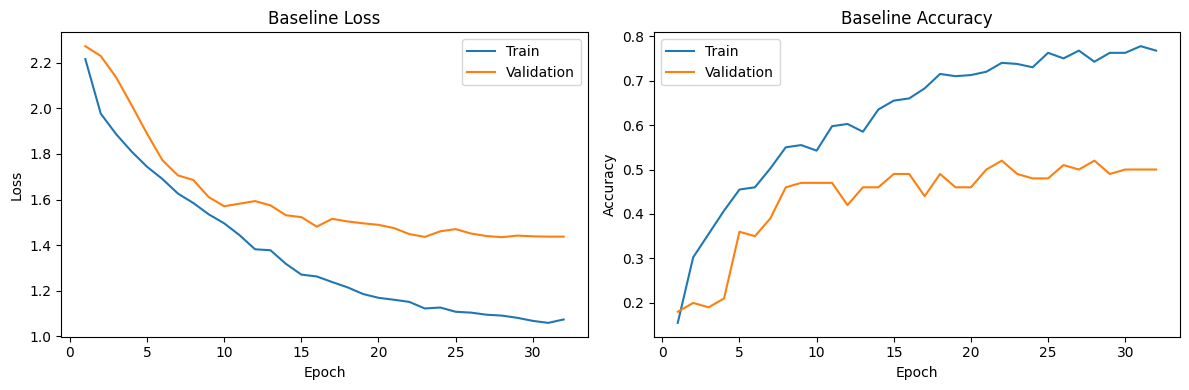

,Validation accuracy,Clean test accuracy,Shifted accuracy (known corruptions only)
0,0.52,0.3993,0.2354


In [8]:
baseline_model, baseline_hist, baseline_loaders = train_model(
    SEEDS[0], augmentation=False, weight_decay=0, dropout=0, smoothing=0
)
plot_history(baseline_hist, "Baseline")
tr,va,cl,sh = baseline_loaders
baseline_results = pd.DataFrame([{
    "Validation accuracy": score(baseline_model,va),
    "Clean test accuracy": score(baseline_model,cl),
    "Shifted accuracy (known corruptions only)": score(baseline_model,sh)
}])
baseline_results

## 9. Parts B/C — Experiments


 No augmentation
seed=42 epoch=01 train_acc=0.155 val_acc=0.180
seed=42 epoch=02 train_acc=0.302 val_acc=0.200
seed=42 epoch=03 train_acc=0.355 val_acc=0.190
seed=42 epoch=04 train_acc=0.407 val_acc=0.210
seed=42 epoch=05 train_acc=0.455 val_acc=0.360
seed=42 epoch=06 train_acc=0.460 val_acc=0.350
seed=42 epoch=07 train_acc=0.502 val_acc=0.390
seed=42 epoch=08 train_acc=0.550 val_acc=0.460
seed=42 epoch=09 train_acc=0.555 val_acc=0.470
seed=42 epoch=10 train_acc=0.542 val_acc=0.470
seed=42 epoch=11 train_acc=0.598 val_acc=0.470
seed=42 epoch=12 train_acc=0.603 val_acc=0.420
seed=42 epoch=13 train_acc=0.585 val_acc=0.460
seed=42 epoch=14 train_acc=0.635 val_acc=0.460
seed=42 epoch=15 train_acc=0.655 val_acc=0.490
seed=42 epoch=16 train_acc=0.660 val_acc=0.490
seed=42 epoch=17 train_acc=0.682 val_acc=0.440
seed=42 epoch=18 train_acc=0.715 val_acc=0.490
seed=42 epoch=19 train_acc=0.710 val_acc=0.460
seed=42 epoch=20 train_acc=0.713 val_acc=0.460
seed=42 epoch=21 train_acc=0.720 val_acc=0

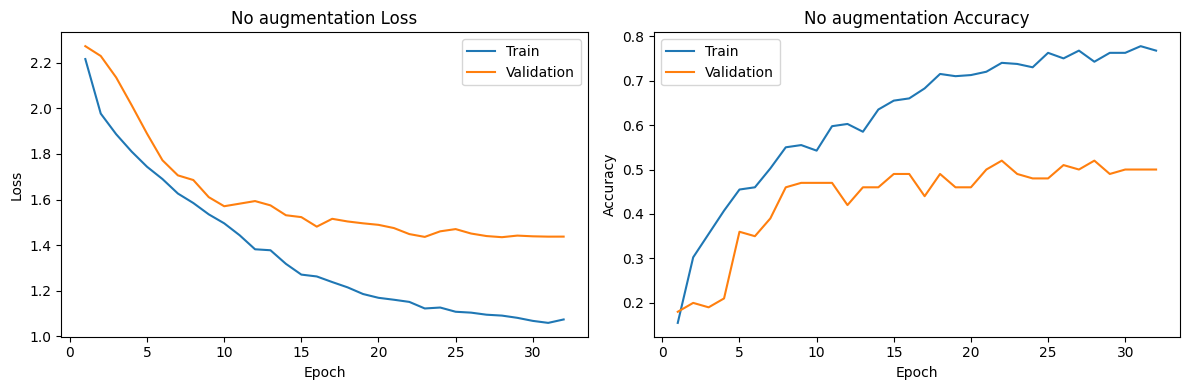


 Geometric + photometric
seed=42 epoch=01 train_acc=0.142 val_acc=0.150
seed=42 epoch=02 train_acc=0.212 val_acc=0.230
seed=42 epoch=03 train_acc=0.268 val_acc=0.250
seed=42 epoch=04 train_acc=0.215 val_acc=0.220
seed=42 epoch=05 train_acc=0.280 val_acc=0.230
seed=42 epoch=06 train_acc=0.278 val_acc=0.310
seed=42 epoch=07 train_acc=0.282 val_acc=0.310
seed=42 epoch=08 train_acc=0.290 val_acc=0.340
seed=42 epoch=09 train_acc=0.302 val_acc=0.270
seed=42 epoch=10 train_acc=0.305 val_acc=0.280
seed=42 epoch=11 train_acc=0.292 val_acc=0.370
seed=42 epoch=12 train_acc=0.335 val_acc=0.350
seed=42 epoch=13 train_acc=0.333 val_acc=0.360
seed=42 epoch=14 train_acc=0.287 val_acc=0.310
seed=42 epoch=15 train_acc=0.357 val_acc=0.290
seed=42 epoch=16 train_acc=0.323 val_acc=0.360
seed=42 epoch=17 train_acc=0.345 val_acc=0.400
seed=42 epoch=18 train_acc=0.347 val_acc=0.350
seed=42 epoch=19 train_acc=0.370 val_acc=0.330
seed=42 epoch=20 train_acc=0.360 val_acc=0.380
seed=42 epoch=21 train_acc=0.378 v

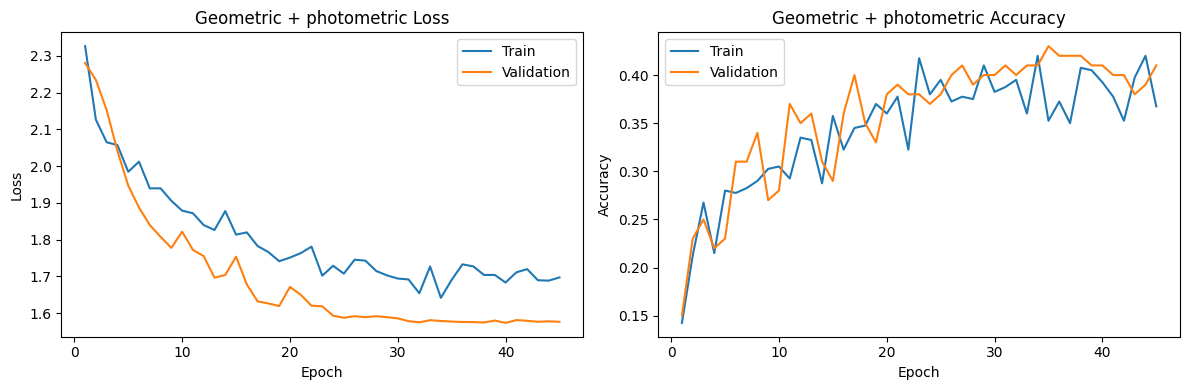


 Augmentation + regularization
seed=42 epoch=01 train_acc=0.107 val_acc=0.150
seed=42 epoch=02 train_acc=0.177 val_acc=0.190
seed=42 epoch=03 train_acc=0.255 val_acc=0.220
seed=42 epoch=04 train_acc=0.217 val_acc=0.280
seed=42 epoch=05 train_acc=0.245 val_acc=0.230
seed=42 epoch=06 train_acc=0.230 val_acc=0.310
seed=42 epoch=07 train_acc=0.280 val_acc=0.340
seed=42 epoch=08 train_acc=0.270 val_acc=0.330
seed=42 epoch=09 train_acc=0.333 val_acc=0.280
seed=42 epoch=10 train_acc=0.253 val_acc=0.280
seed=42 epoch=11 train_acc=0.278 val_acc=0.330
seed=42 epoch=12 train_acc=0.333 val_acc=0.300
seed=42 epoch=13 train_acc=0.315 val_acc=0.320
seed=42 epoch=14 train_acc=0.275 val_acc=0.310
seed=42 epoch=15 train_acc=0.340 val_acc=0.320
seed=42 epoch=16 train_acc=0.310 val_acc=0.330
seed=42 epoch=17 train_acc=0.323 val_acc=0.370
seed=42 epoch=18 train_acc=0.323 val_acc=0.360
seed=42 epoch=19 train_acc=0.345 val_acc=0.330
seed=42 epoch=20 train_acc=0.323 val_acc=0.350
seed=42 epoch=21 train_acc=0

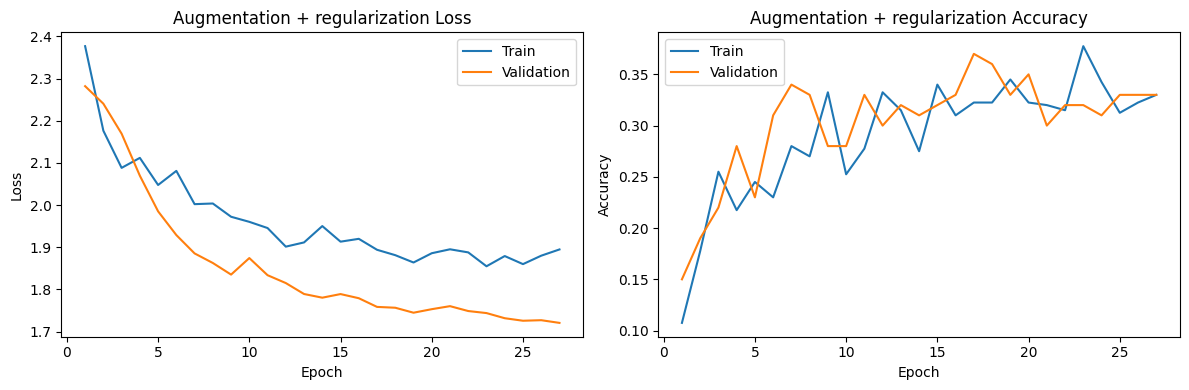

,Configuration,Validation accuracy,Clean test accuracy (exploratory),Shifted accuracy (known corruptions only; exploratory)
0,No augmentation,0.52,0.3993,0.2354
1,Geometric + photometric,0.43,0.3302,0.2738
2,Augmentation + regularization,0.37,0.3108,0.2591


In [9]:
configs = [
    {"name":"No augmentation","augmentation":False,"weight_decay":0.,"dropout":0.,"smoothing":0.},
    {"name":"Geometric + photometric","augmentation":True,"weight_decay":1e-4,"dropout":.25,"smoothing":0.},
    {"name":"Augmentation + regularization","augmentation":True,"weight_decay":5e-4,"dropout":.35,"smoothing":.05},
]
experiment_rows, experiment_models, experiment_histories = [], {}, {}
for cfg in configs:
    print("\n",cfg["name"])
    model,hist,loaders = train_model(SEEDS[0], cfg["augmentation"], cfg["weight_decay"], cfg["dropout"], cfg["smoothing"])
    _,va,cl,sh = loaders
    experiment_rows.append({
        "Configuration":cfg["name"], "Validation accuracy":score(model,va),
        "Clean test accuracy (exploratory)":score(model,cl),
        "Shifted accuracy (known corruptions only; exploratory)":score(model,sh)
    })
    experiment_models[cfg["name"]]=model; experiment_histories[cfg["name"]]=hist
    plot_history(hist,cfg["name"])
experiment_table = pd.DataFrame(experiment_rows)
experiment_table

**Reminder:** Strict assignment protocol says use validation for choosing settings and test sets only for final evaluation. The test metrics above are exploratory scaffolding; for a strict final run, select the configuration using validation only, then evaluate test data once.

## 10. Part D — Required ablations

In [10]:
# TODO: Implement and run the remaining required configurations:
# 1) Geometric only
# 2) Photometric only
# 3) Geometric + photometric
# 4) + Cutout / Random Erasing
# 5) + Mixup/CutMix + label smoothing
# 6) Final selected model
# Add each measured result to this table; do not fill with guessed values.
ablation_table = pd.DataFrame([
    {"Configuration":"No augmentation","Validation accuracy":np.nan,"Clean test":np.nan,"Shifted test":np.nan,"Shifted mean ± std (3 seeds)":""},
    {"Configuration":"Geometric only","Validation accuracy":np.nan,"Clean test":np.nan,"Shifted test":np.nan,"Shifted mean ± std (3 seeds)":""},
    {"Configuration":"Photometric only","Validation accuracy":np.nan,"Clean test":np.nan,"Shifted test":np.nan,"Shifted mean ± std (3 seeds)":""},
    {"Configuration":"Geometric + photometric","Validation accuracy":np.nan,"Clean test":np.nan,"Shifted test":np.nan,"Shifted mean ± std (3 seeds)":""},
    {"Configuration":"+ Cutout / Random Erasing","Validation accuracy":np.nan,"Clean test":np.nan,"Shifted test":np.nan,"Shifted mean ± std (3 seeds)":""},
    {"Configuration":"+ Mixup/CutMix + label smoothing","Validation accuracy":np.nan,"Clean test":np.nan,"Shifted test":np.nan,"Shifted mean ± std (3 seeds)":""},
    {"Configuration":"Final selected model","Validation accuracy":np.nan,"Clean test":np.nan,"Shifted test":np.nan,"Shifted mean ± std (3 seeds)":""},
])
ablation_table

,Configuration,Validation accuracy,Clean test,Shifted test,Shifted mean ± std (3 seeds)
0,No augmentation,NaN,NaN,NaN,
1,Geometric only,NaN,NaN,NaN,
2,Photometric only,NaN,NaN,NaN,
3,Geometric + photometric,NaN,NaN,NaN,
4,+ Cutout / Random Erasing,NaN,NaN,NaN,
5,+ Mixup/CutMix + label smoothing,NaN,NaN,NaN,
6,Final selected model,NaN,NaN,NaN,


## 11. Part E — Per-class accuracy and confusion matrix

              precision    recall  f1-score   support

    airplane      0.341     0.464     0.393      1000
  automobile      0.472     0.263     0.338      1000
        bird      0.274     0.269     0.271      1000
         cat      0.210     0.119     0.152      1000
        deer      0.260     0.265     0.262      1000
         dog      0.245     0.616     0.350      1000
        frog      0.418     0.359     0.386      1000
       horse      0.562     0.054     0.099      1000
        ship      0.311     0.541     0.395      1000
       truck      0.520     0.158     0.242      1000

    accuracy                          0.311     10000
   macro avg      0.361     0.311     0.289     10000
weighted avg      0.361     0.311     0.289     10000



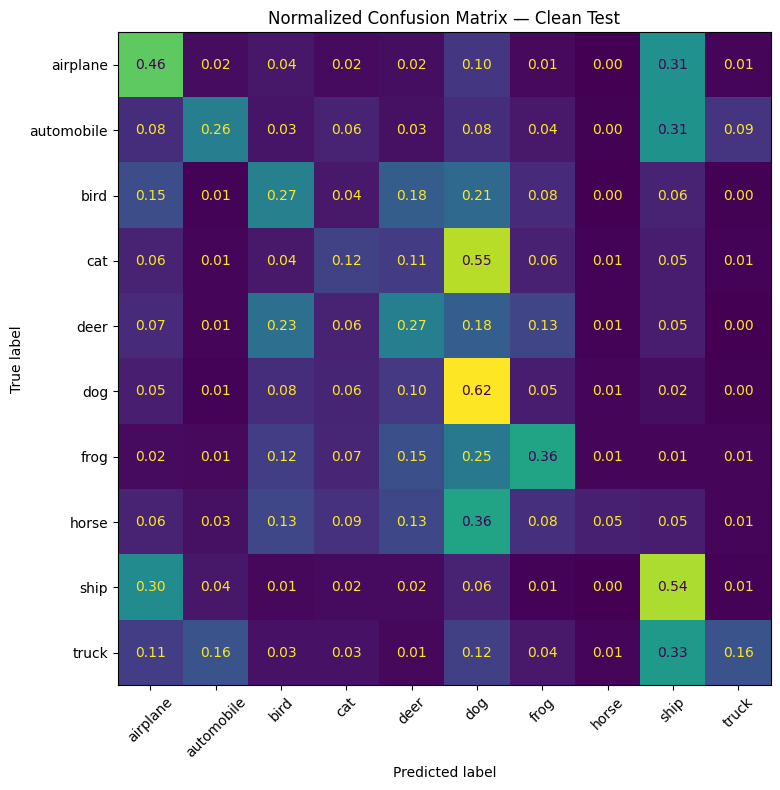

,Class,Accuracy
0,airplane,0.464
1,automobile,0.263
2,bird,0.269
3,cat,0.119
4,deer,0.265
5,dog,0.616
6,frog,0.359
7,horse,0.054
8,ship,0.541
9,truck,0.158


In [11]:
# Replace with the model selected using validation results.
final_model = experiment_models["Augmentation + regularization"]
_, val_loader, clean_loader, shifted_loader = make_loaders(SEEDS[0], augmentation=True)
y_true,y_pred,y_probs,test_images = predict(final_model,clean_loader)
print(classification_report(y_true,y_pred,target_names=CLASS_NAMES,digits=3))
cm = confusion_matrix(y_true,y_pred,normalize="true")
fig,ax = plt.subplots(figsize=(10,8))
ConfusionMatrixDisplay(cm,display_labels=CLASS_NAMES).plot(ax=ax,xticks_rotation=45,values_format=".2f",colorbar=False)
plt.title("Normalized Confusion Matrix — Clean Test"); plt.tight_layout(); plt.show()

rows=[]
for c,name in enumerate(CLASS_NAMES):
    mask = y_true==c
    rows.append({"Class":name,"Accuracy":float((y_pred[mask]==y_true[mask]).mean())})
pd.DataFrame(rows)

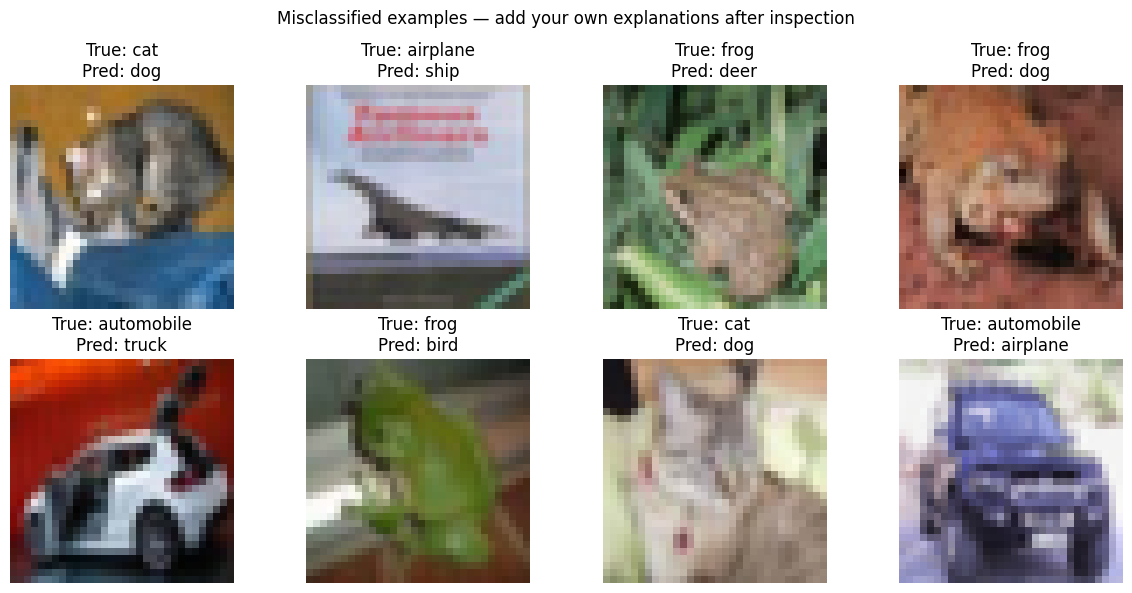

In [12]:
wrong = np.where(y_true != y_pred)[0]
n = min(8,len(wrong))
fig,axes = plt.subplots(2,4,figsize=(12,6))
for ax,idx in zip(axes.flat,wrong[:n]):
    ax.imshow(test_raw[idx][0])
    ax.set_title(f"True: {CLASS_NAMES[y_true[idx]]}\nPred: {CLASS_NAMES[y_pred[idx]]}")
    ax.axis("off")
for ax in list(axes.flat)[n:]: ax.axis("off")
plt.suptitle("Misclassified examples — add your own explanations after inspection")
plt.tight_layout(); plt.show()

## 12. Three-seed evaluation

In [14]:
# After selecting the final configuration using validation results, set these values accordingly.
FINAL = {"augmentation":True,"weight_decay":5e-4,"dropout":.35,"smoothing":.05}
seed_rows=[]
for seed in SEEDS:
    print("\nFinal run, seed:",seed)
    model,hist,loaders = train_model(seed,FINAL["augmentation"],FINAL["weight_decay"],FINAL["dropout"],FINAL["smoothing"])
    _,va,cl,sh = loaders
    seed_rows.append({"Seed":seed,"Validation":score(model,va),"Clean test":score(model,cl),
                      "Shifted (known corruptions only)":score(model,sh)})
three_seed_results = pd.DataFrame(seed_rows)
display(three_seed_results)

display(three_seed_results.drop(columns="Seed").agg(["mean","std"]))


Final run, seed: 42
seed=42 epoch=01 train_acc=0.107 val_acc=0.150
seed=42 epoch=02 train_acc=0.177 val_acc=0.190
seed=42 epoch=03 train_acc=0.255 val_acc=0.220
seed=42 epoch=04 train_acc=0.217 val_acc=0.280
seed=42 epoch=05 train_acc=0.245 val_acc=0.230
seed=42 epoch=06 train_acc=0.230 val_acc=0.310
seed=42 epoch=07 train_acc=0.280 val_acc=0.340
seed=42 epoch=08 train_acc=0.270 val_acc=0.330
seed=42 epoch=09 train_acc=0.333 val_acc=0.280
seed=42 epoch=10 train_acc=0.253 val_acc=0.280
seed=42 epoch=11 train_acc=0.278 val_acc=0.330
seed=42 epoch=12 train_acc=0.333 val_acc=0.300
seed=42 epoch=13 train_acc=0.315 val_acc=0.320
seed=42 epoch=14 train_acc=0.275 val_acc=0.310
seed=42 epoch=15 train_acc=0.340 val_acc=0.320
seed=42 epoch=16 train_acc=0.310 val_acc=0.330
seed=42 epoch=17 train_acc=0.323 val_acc=0.370
seed=42 epoch=18 train_acc=0.323 val_acc=0.360
seed=42 epoch=19 train_acc=0.345 val_acc=0.330
seed=42 epoch=20 train_acc=0.323 val_acc=0.350
seed=42 epoch=21 train_acc=0.320 val_ac

,Seed,Validation,Clean test,Shifted (known corruptions only)
0,42,0.37,0.3108,0.2591
1,123,0.36,0.2851,0.2325
2,2026,0.44,0.3210,0.2447


,Validation,Clean test,Shifted (known corruptions only)
mean,0.390000,0.305633,0.245433
std,0.043589,0.018499,0.013315


## 13. Part F — Optional test-time augmentation

In [15]:
@torch.no_grad()
def evaluate_flip_tta(model,loader):
    model.eval(); correct=total=0; start=time.perf_counter()
    for x,y in loader:
        x,y=x.to(DEVICE),y.to(DEVICE)
        probs=(torch.softmax(model(x),1)+torch.softmax(model(torch.flip(x,[3])),1))/2
        correct += (probs.argmax(1)==y).sum().item(); total += len(y)
    return correct/total, time.perf_counter()-start

# TODO: Run after the final model is fixed and compare against normal inference.
# tta_acc, seconds = evaluate_flip_tta(final_model, shifted_loader)
# print("TTA accuracy:", tta_acc, "Elapsed seconds:", seconds)

## 14. Save result tables

In [ ]:
baseline_results.to_csv("/kaggle/working/baseline_results.csv",index=False)
experiment_table.to_csv("/kaggle/working/experiment_results.csv",index=False)
three_seed_results.to_csv("/kaggle/working/three_seed_results.csv",index=False)
print("Saved result CSV files in /kaggle/working/")

## 15. Final checklist
- [ ] Add the exact hidden corruption from the instructor.
- [ ] Implement all required ablations, including Cutout/Random Erasing and Mixup/CutMix.
- [ ] Choose final hyperparameters using validation data only.
- [ ] Run final test evaluation and report three-seed mean ± standard deviation.
- [ ] Explain the largest clean-vs-shifted gap and the most confused classes.
- [ ] Inspect at least eight errors and write your own reasons.
- [ ] Use only measured results in the one-page summary and README.